# pr1 · Block matrices and partitioned algorithms

In [1]:
import numpy as np, scipy.linalg as sla, pandas as pd, matplotlib.pyplot as plt
from time import perf_counter
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)

## Ex.1 · `C = AB + C` and the 6 loop orders
Same `2n³` flops, different inner loop. Pure triple loop (scalar):

In [2]:
def gemm(A, B, C, order="ijk"):
    '''C <- AB + C with the three loops nested in the given order.'''
    C = C.copy(); n = A.shape[0]
    for a in range(n):
        for b in range(n):
            for c in range(n):
                idx = dict(zip(order, (a, b, c)))
                i, j, k = idx["i"], idx["j"], idx["k"]
                C[i, j] += A[i, k] * B[k, j]
    return C

n = 30
A, B, C = (rng.standard_normal((n, n)) for _ in range(3))
orders = ["ijk", "jik", "ikj", "jki", "kij", "kji"]
print(f"n = {n}   max |gemm - (AB+C)|")
for o in orders:
    print(f"  {o}: {np.abs(gemm(A, B, C, o) - (A @ B + C)).max():.2e}")

n = 30   max |gemm - (AB+C)|
  ijk: 5.33e-15
  jik: 5.33e-15
  ikj: 5.33e-15
  jki: 5.33e-15
  kij: 5.33e-15
  kji: 5.33e-15


With the innermost loop vectorized we can see the effect of the inner operation (NumPy is row-major):

| order | inner loop | access |
|---|---|---|
| ijk, jik | dot product | row of A · column of B |
| ikj, kij | row saxpy `C[i,:] += a_ik B[k,:]` | rows (contiguous) |
| jki, kji | column saxpy `C[:,j] += b_kj A[:,k]` | columns (strided) |

In [3]:
def gemm_vec(A, B, C, order):
    C = C.copy(); n = A.shape[0]
    if order == "ijk":
        for i in range(n):
            for j in range(n): C[i, j] += A[i, :] @ B[:, j]
    elif order == "jik":
        for j in range(n):
            for i in range(n): C[i, j] += A[i, :] @ B[:, j]
    elif order == "ikj":
        for i in range(n):
            for k in range(n): C[i, :] += A[i, k] * B[k, :]
    elif order == "kij":
        for k in range(n):
            for i in range(n): C[i, :] += A[i, k] * B[k, :]
    elif order == "jki":
        for j in range(n):
            for k in range(n): C[:, j] += B[k, j] * A[:, k]
    elif order == "kji":
        for k in range(n):
            for j in range(n): C[:, j] += B[k, j] * A[:, k]
    return C

n = 400
A, B, C = (rng.standard_normal((n, n)) for _ in range(3))
ref = A @ B + C
rows = []
for o in orders:
    t = perf_counter(); R = gemm_vec(A, B, C, o); t = perf_counter() - t
    rows.append([o, t, np.abs(R - ref).max()])
pd.DataFrame(rows, columns=["order", "time [s]", "max error"]).set_index("order").style.format({"time [s]": "{:.3f}", "max error": "{:.1e}"})

,time [s],max error
order,,
ijk,1.024,7.8e-14
jik,0.714,7.8e-14
ikj,0.648,1.1e-13
jki,0.770,1.1e-13
kij,0.555,1.1e-13
kji,0.948,1.1e-13


## Ex.2 · Block matrix multiplication
`C_IJ += Σ_K A_IK B_KJ` with `b×b` blocks (Demmel p.69).

In [4]:
def gemm_block(A, B, C, b):
    C = C.copy(); n = A.shape[0]
    for I in range(0, n, b):
        for J in range(0, n, b):
            for K in range(0, n, b):
                C[I:I+b, J:J+b] += A[I:I+b, K:K+b] @ B[K:K+b, J:J+b]
    return C

n = 1024
A, B, C = (rng.standard_normal((n, n)) for _ in range(3))
ref = A @ B + C
rows = []
for b in [16, 32, 64, 128, 256, 512, 1024]:
    t = perf_counter(); R = gemm_block(A, B, C, b); t = perf_counter() - t
    rows.append([b, (n // b) ** 3, t, np.abs(R - ref).max()])
df = pd.DataFrame(rows, columns=["b", "# block products", "time [s]", "max error"]).set_index("b")
df.style.format({"time [s]": "{:.3f}", "max error": "{:.1e}"})

,# block products,time [s],max error
b,,,
16,262144,4.120,1.1e-13
32,32768,0.988,1.1e-13
64,4096,0.516,9.9e-14
128,512,0.106,3.6e-14
256,64,0.045,4.3e-14
512,8,0.037,4.3e-14
1024,1,0.040,0.0e+00


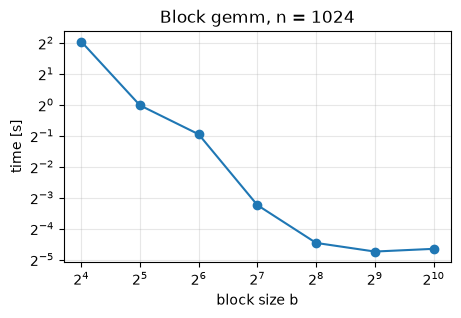

In [5]:
plt.figure(figsize=(5, 3))
plt.loglog(df.index, df["time [s]"], "o-", base=2)
plt.xlabel("block size b"); plt.ylabel("time [s]"); plt.title(f"Block gemm, n = {n}")
plt.grid(alpha=.3); plt.show()

Small blocks → Python overhead of many tiny products dominates; large blocks → few calls to optimized level-3 BLAS.

## Ex.3 · Block-partitioned LU
1. `A11 = L11 U11` (no pivoting) 2. `L11 U12 = A12` 3. `L21 U11 = A21` 4. `S = A22 − L21 U12` 5. repeat on `S`.

First, LU without pivoting (Algorithm 1.3.2 of the notes without the row swap):

In [6]:
def lu_nopiv(A):
    '''Gaussian elimination without pivoting. Returns unit-lower L and upper U.'''
    A = np.array(A, dtype=float); n = A.shape[0]
    for j in range(n - 1):
        if A[j, j] == 0: raise ZeroDivisionError(f"zero pivot at step {j}")
        A[j+1:, j] /= A[j, j]                                  # j-th column of L
        A[j+1:, j+1:] -= np.outer(A[j+1:, j], A[j, j+1:])      # Schur complement
    return np.tril(A, -1) + np.eye(n), np.triu(A)

def lu_block(A, r):
    '''Block-partitioned LU with blocks of size r. Triangular systems solved with LU + pivoting.'''
    A = np.array(A, dtype=float); n = A.shape[0]
    L, U = np.eye(n), np.zeros((n, n))
    for k in range(0, n, r):
        e = min(k + r, n)
        L11, U11 = lu_nopiv(A[k:e, k:e])                                   # i)
        L[k:e, k:e], U[k:e, k:e] = L11, U11
        if e < n:
            U12 = sla.lu_solve(sla.lu_factor(L11), A[k:e, e:])             # ii)  L11 U12 = A12
            L21 = sla.lu_solve(sla.lu_factor(U11), A[e:, k:e].T, trans=1).T  # iii) U11^T L21^T = A21^T
            U[k:e, e:], L[e:, k:e] = U12, L21
            A[e:, e:] -= L21 @ U12                                         # iv)  Schur complement
    return L, U                                                            # v)  loop = repeat on S

In [7]:
A = np.array([[2., 1, 1, 0], [4, 3, 3, 1], [8, 7, 9, 5], [6, 7, 9, 8]])
L, U = lu_block(A, r=2)
print("L =\n", L, "\nU =\n", U, "\n||A - LU|| =", np.linalg.norm(A - L @ U))

L =
 [[1. 0. 0. 0.]
 [2. 1. 0. 0.]
 [4. 3. 1. 0.]
 [3. 4. 1. 1.]] 
U =
 [[2. 1. 1. 0.]
 [0. 1. 1. 1.]
 [0. 0. 2. 2.]
 [0. 0. 0. 2.]] 
||A - LU|| = 0.0


In [8]:
n = 600
A = rng.standard_normal((n, n)) + n * np.eye(n)       # diagonally dominant -> no pivoting needed
L0, U0 = lu_nopiv(A)
rows = []
for r in [8, 32, 64, 128, 300, 600]:
    t = perf_counter(); L, U = lu_block(A, r); t = perf_counter() - t
    rows.append([r, t, np.linalg.norm(A - L @ U) / np.linalg.norm(A),
                 max(np.abs(L - L0).max(), np.abs(U - U0).max())])
pd.DataFrame(rows, columns=["r", "time [s]", "||A-LU||/||A||", "max diff vs unblocked LU"]).set_index("r") \
  .style.format({"time [s]": "{:.3f}", "||A-LU||/||A||": "{:.1e}", "max diff vs unblocked LU": "{:.1e}"})

,time [s],||A-LU||/||A||,max diff vs unblocked LU
r,,,
8,0.141,3.6e-16,2.2e-12
32,0.047,2.7e-16,2.3e-12
64,0.038,3.3e-16,1.9e-12
128,0.043,4.4e-16,1.8e-12
300,0.087,7.1e-16,1.6e-12
600,0.495,9.6e-16,0.0e+00


Same factors as the unblocked LU (up to rounding) for every `r`: it is the classical LU, just organised in blocks.